# Part 3 — Image Transformation (plantCV)
1. Gaussian Blur  2. Mask  3. ROI Objects  4. Analyze Object  5. Pseudolandmarks  6. Color Histogram

When converted to a script, supports CLI flags:
- `./Transformation.py <image_path>` — display transformations for a single image
- `./Transformation.py -src <dir> -dst <dir> -mask` — save transformations for all images in directory
- `./Transformation.py -h` — show help

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import argparse

import cv2
import matplotlib.pyplot as plt
import numpy as np
import plantcv.plantcv as pcv


from src.data import LeafLoader
from src.features import LeafTransformer

I0000 00:00:1788095944.152176  125939 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1788095945.019189  125939 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
loader = LeafLoader()

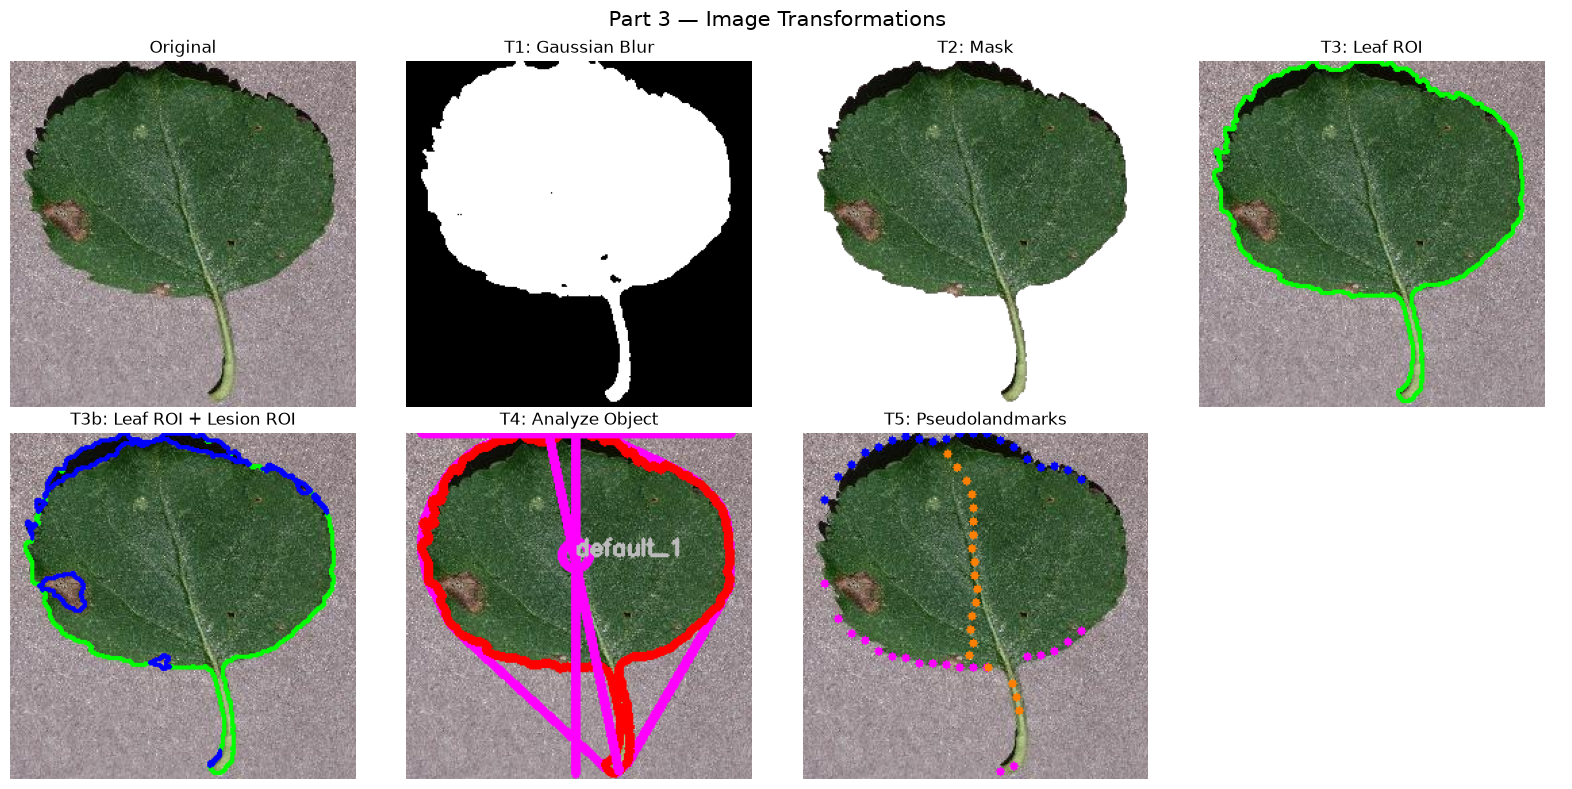


Shape metrics (leaf ROI):
  area                  31928.0000
  perimeter             911.7788
  solidity              0.8296
  convex_hull_area      38484.0000
  longest_path          255.3507
  ellipse_eccentricity  0.5201
  width                 229.0000
  height                252.0000
  circularity           0.4826
  extent                0.5533

Disease severity (leaf ROI vs lesion ROI):
  leaf_area_px          31928
  lesion_area_px        2325
  severity_pct          7.2820


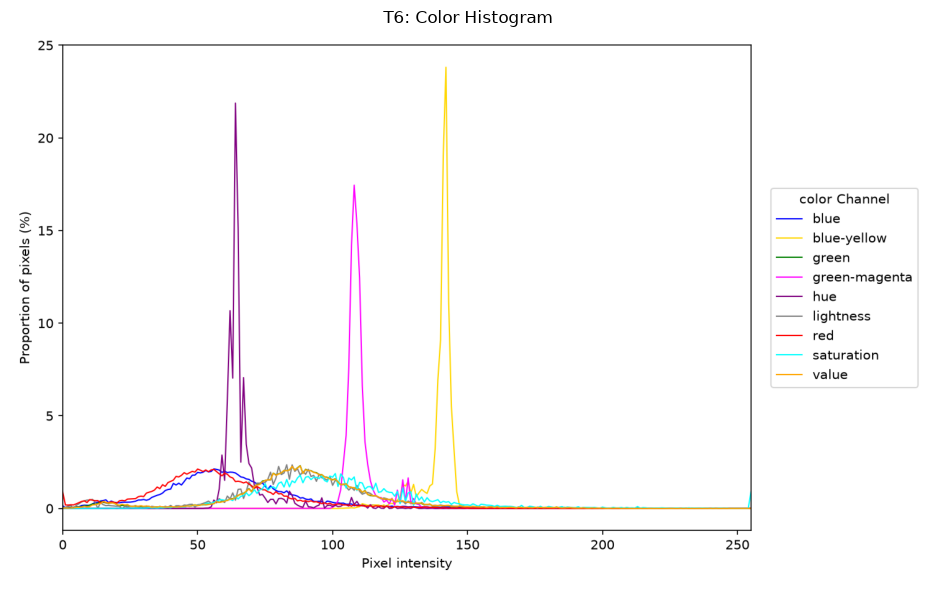

In [3]:
img_path = Path("../data/leaves/images/Apple_Black_rot/image (1).JPG")
rgb = loader.load_rgb(img_path)
transformer = LeafTransformer(
    loader=loader,
    s_threshold=53,
    blur_ksize=(3, 3),
    rethreshold=100,
    blur_sigma=2,
    fill_size=400,
    # -- T3 ROI outline --
    roi_color=(0, 255, 0),
    roi_thickness=2,
    # -- T5 pseudolandmarks --
    landmark_radius=3,
    landmark_colors=((0, 0, 255), (255, 0, 255), (255, 128, 0)),  # top, bottom, center_v
    # -- T6 color histogram --
    hist_figsize=(10, 6),
    hist_dpi=150,
)
transformer.display_results(transformer.transform(rgb))